# Apprentissage non supervisé avec critère personnalisé

En non supervisé, il n'y a **pas de labels**. Ici, au lieu de se reconstruire (autoencodeur),
le modèle apprend une **structure géométrique des données** grâce à un critère custom :
on projette des points bruités sur le cercle unité, sans jamais donner de coordonnées cibles.

In [9]:
from NeuralNetworks import MLP, Trainer, losses, learnings
import torch

## Données

Des points 2D tirés aléatoirement autour du cercle unité (rayon 1 + bruit), **sans aucun label**.

In [10]:
torch.manual_seed(0)
angles = torch.rand(400, 1) * 2 * torch.pi
radius = 1 + 0.1 * torch.randn(400, 1)
X = torch.cat([radius * torch.cos(angles), radius * torch.sin(angles)], dim=1)   # [400, 2]

## Critère custom non supervisé

Le `Trainer` accepte **n'importe quel callable** `crit(net, inputs, outputs)`.
Ici la loss pénalise la distance des sorties au cercle unité : `(‖net(x)‖² − 1)²`.
Aucune cible `y` n'intervient : c'est le critère lui-même qui définit la tâche.

> Un critère custom sert aussi à faire du **vrai supervisé** : il suffit d'y embarquer les labels
> (ex. `loss = (net(x) - y).pow(2).mean()` dans une closure) — le `Trainer` ne fait que l'appeler.

In [11]:
def cercle_crit(net, xb, _):
    y = net.train_forward(xb)
    return ((y.pow(2).sum(dim=1) - 1) ** 2).mean()   # distance au cercle unité

In [12]:
net = MLP(input_size=2, output_size=2, hidden_layers=[16, 16], norm="Tanh", name="Cercle")

## Entraînement

On ne passe pas `outputs` : le critère custom n'en a pas besoin.

In [13]:
trainer = Trainer(net,
                  inputs=X,
                  init_train_size=1.0, final_train_size=1.0,
                  crit=cercle_crit, optim="Adam",
                  init_lr=1e-2, final_lr=1e-4,
                  batch_size=64)
trainer.train(500)

Training Cercle:   0%|          | 0/500 [00:00<?, ?epoch/s]

## Visualiser l'entraînement

Les courbes de perte et de learning rate se tracent avec `losses(net)` et `learnings(net)`.

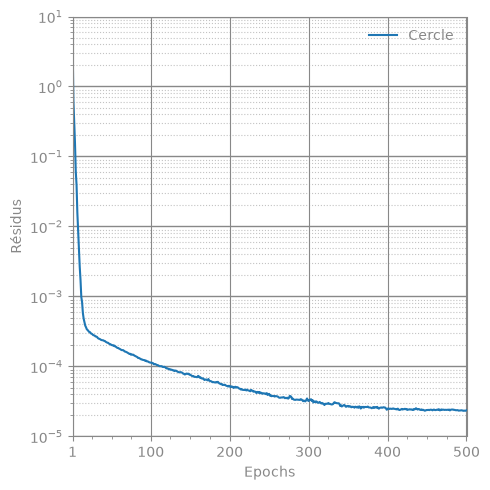

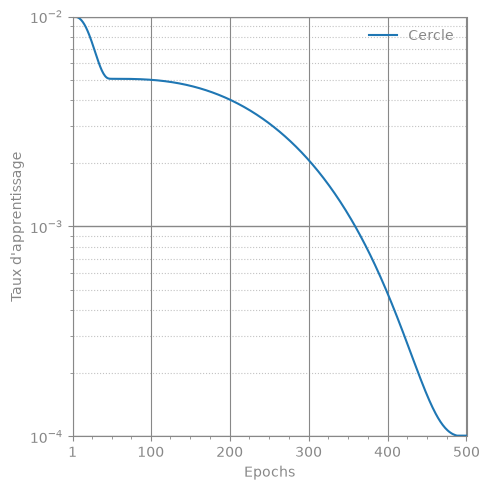

In [14]:
losses(net)
learnings(net)

## Résultat

Les sorties du réseau doivent toutes se trouver sur le cercle unité (rayon ≈ 1).

In [15]:
r = net(X).pow(2).sum(dim=1).sqrt()
print("Rayon moyen des sorties :", r.mean().item(), "(cible : 1.0)")

Rayon moyen des sorties : 1.000044345855713 (cible : 1.0)


## Remarque : critère prédéfini sans `outputs` = autoencodeur

Si on omet `outputs` **et** qu'on utilise un critère prédéfini (ex. `"MSE"`),
le `Trainer` compare le réseau à ses propres entrées : c'est un **autoencodeur**.
L'exemple ci-dessous compresse des vecteurs 10D en 3D et les reconstruit :

In [16]:
X10 = torch.rand(500, 10)
ae = MLP(input_size=10, output_size=10, hidden_layers=[3], norm="Relu", name="Autoencodeur")

trainer_ae = Trainer(ae,
                     inputs=X10,
                     init_train_size=1.0, final_train_size=1.0,
                     crit="MSE", optim="Adam",
                     init_lr=1e-3, final_lr=1e-5,
                     batch_size=64)
trainer_ae.train(500)

recon = ae(X10)
print("Erreur de reconstruction moyenne :", (recon - X10).pow(2).mean().item())

Training Autoencodeur:   0%|          | 0/500 [00:00<?, ?epoch/s]

Erreur de reconstruction moyenne : 0.08162829279899597
